Uploaded 4 of my cleaned data sets that have 3-point and mid-range stats for guards in the 2003-2004 and 2004-2005 season (to check impact of hand-checking ban)

In [2]:
from google.colab import files
uploaded = files.upload()   # upload all 4 CSVs: 3pt 2003-04 / 2004-05 and mid 2003-04 / 2004-05

Saving filtered3pt2003-2004 - Sheet1.csv to filtered3pt2003-2004 - Sheet1.csv
Saving filtered3pt2004-2005 - Sheet1.csv to filtered3pt2004-2005 - Sheet1.csv
Saving filteredmid2004-2005 - Sheet1.csv to filteredmid2004-2005 - Sheet1.csv
Saving filteredmid2003-2004 - Sheet1.csv to filteredmid2003-2004 - Sheet1.csv


Organized the 4 data sets by gathering players that were in the 2003-2004 and 2004-2005 data sets, putting their stats side-by-side for mid-range and 3-point stats, respectively.

In [3]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
PAL = {"2003-04": "#8c8c8c", "2004-05": "#d1495b"}   # grey = before ban, red = after

# ---- 3-point (same logic as your 3ptfiltered notebook) ----
f04 = "filtered3pt2003-2004 - Sheet1.csv"
f05 = "filtered3pt2004-2005 - Sheet1.csv"
a, b = pd.read_csv(f04), pd.read_csv(f05)
for d in (a, b):
    d.columns = [str(c).strip() for c in d.columns]
    d['clean_name'] = d['Player'].astype(str).str.strip()
a = a[~a.clean_name.isin(['nan', ''])].drop_duplicates('clean_name')
b = b[~b.clean_name.isin(['nan', ''])].drop_duplicates('clean_name')
m = pd.merge(a, b, on='clean_name', suffixes=('_0304', '_0405'))
three_df = m[['clean_name', '3:00 PM_0304', '3:00 PM_0405', '3PA_0304', '3PA_0405', '3P%_0304', '3P%_0405']].copy()
three_df.columns = ['Player', '3PM_0304', '3PM_0405', '3PA_0304', '3PA_0405', '3P%_0304', '3P%_0405']

# ---- Mid-range (same logic as your midfiltered notebook) ----
r04 = pd.read_csv("filteredmid2003-2004 - Sheet1.csv", header=None)
r04 = r04[pd.to_numeric(r04[4], errors='coerce').notna()]
r05 = pd.read_csv("filteredmid2004-2005 - Sheet1.csv", header=None)
r05 = r05[pd.to_numeric(r05[4], errors='coerce').notna()]
def prep(raw, tag):
    out = pd.DataFrame({'Player': raw[0].astype(str).str.strip()})
    for col, nm in [(11, 'MidFGM'), (12, 'MidFGA'), (13, 'MidFG%')]:
        out[f'{nm}_{tag}'] = pd.to_numeric(raw[col], errors='coerce')
    return out.drop_duplicates('Player')
mid_df = pd.merge(prep(r04, '0304'), prep(r05, '0405'), on='Player')

print(len(three_df), "players in 3PT table;", len(mid_df), "in mid-range table")

100 players in 3PT table; 98 in mid-range table


Wanted to display basic 3-point and mid-range stats (median, median, standard deviation) between the 2 seasons to help build visualizations. Also was helpful to see whether or not there were any significant changes (most changes were minute)

3PM = 3-points made, 3PA = 3-point attempts, 3% = 3-point percentage
MIDFGM = Mid-range field goals made, MIDFGA = Mid-range field goals attempted, MIDFG% = Mid-range field goal percentage

In [4]:
def make_long(df, stats):
    out = {}
    for s in stats:
        x, y = f"{s}_0304", f"{s}_0405"
        out[s] = pd.concat([
            df[['Player', x]].rename(columns={x: 'value'}).assign(Season='2003-04'),
            df[['Player', y]].rename(columns={y: 'value'}).assign(Season='2004-05')
        ]).dropna()
    return out

three_long = make_long(three_df, ['3PM', '3PA', '3P%'])
mid_long   = make_long(mid_df,   ['MidFGM', 'MidFGA', 'MidFG%'])
sets = {"3-Point": (three_df, three_long), "Mid-Range": (mid_df, mid_long)}

for name, (df, lg) in sets.items():
    print(f"\n=== {name} ===")
    print(pd.concat({s: d.groupby('Season')['value'].agg(['mean', 'median', 'std'])
                     for s, d in lg.items()}).round(2))


=== 3-Point ===
              mean  median   std
    Season                      
3PM 2003-04   0.99    0.95  0.69
    2004-05   1.05    0.95  0.76
3PA 2003-04   2.86    2.75  1.87
    2004-05   2.90    2.50  1.95
3P% 2003-04  32.20   33.20  7.49
    2004-05  33.01   35.50  8.77

=== Mid-Range ===
                 mean  median   std
       Season                      
MidFGM 2003-04   1.49    1.35  0.89
       2004-05   1.53    1.40  0.85
MidFGA 2003-04   3.84    3.55  2.14
       2004-05   3.82    3.30  2.03
MidFG% 2003-04  37.99   38.50  4.99
       2004-05  39.86   39.60  4.72


Displayed stats in box plots side-by-side. For most categories, the median barely changed (even decreased for MidFGA and 3PA). However, the distribution became less symmetric -> skewed to the right (the mean increased). This could suggest a select number of players (in the 3rd and 4th quartile specifically) took advantage of the new rule change.

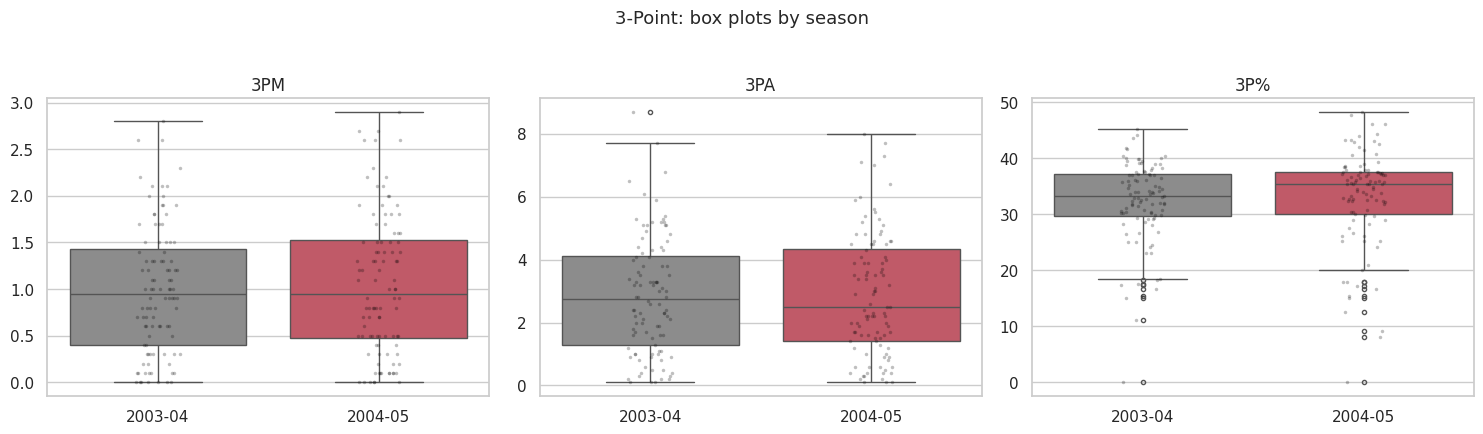

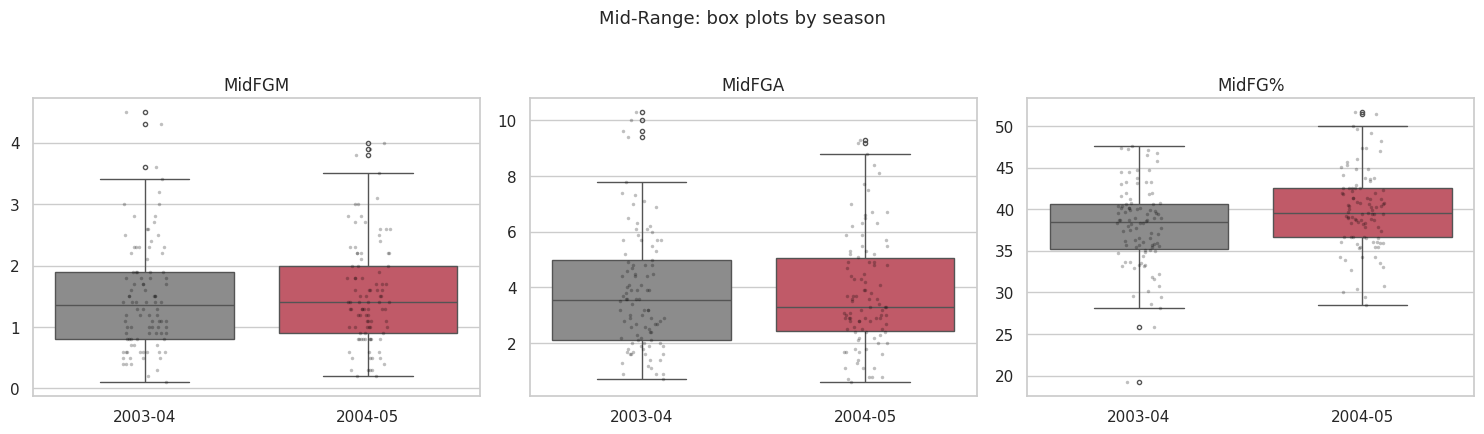

In [5]:
def grid(lg, title, kind):
    fig, axes = plt.subplots(1, len(lg), figsize=(5 * len(lg), 4.2))
    for ax, (s, d) in zip(np.atleast_1d(axes), lg.items()):
        if kind == 'box':
            sns.boxplot(data=d, x='Season', y='value', hue='Season', palette=PAL, legend=False, ax=ax, fliersize=3)
            sns.stripplot(data=d, x='Season', y='value', color='black', alpha=.25, size=2.5, ax=ax)
        elif kind == 'density':
            sns.kdeplot(data=d, x='value', hue='Season', palette=PAL, fill=True, common_norm=False, alpha=.35, ax=ax)
        elif kind == 'hist':
            sns.histplot(data=d, x='value', hue='Season', palette=PAL, bins=15, stat='density',
                         common_norm=False, element='step', alpha=.35, ax=ax)
        ax.set_title(s); ax.set_xlabel(s if kind != 'box' else ''); ax.set_ylabel('')
    fig.suptitle(title, y=1.03, fontsize=13)
    plt.tight_layout(); plt.show()

for name, (df, lg) in sets.items():
    grid(lg, f"{name}: box plots by season", 'box')

Density distribution for same stats: y-axis represents probability density. HIgher "probability" indicates more players clustered in that area.
Graph is "smoothed out" by "kernel density estimation", thus why there are "negative" values in the x-axis.
We could observe most distributions had slight difference between the 2003-2004 and 2004-2005 seasons, but nothing notable. The 3P% and MidFG% distributions seemed to have the mosg significant results, showing that the dsitribution moved to the right (higher made percentage)

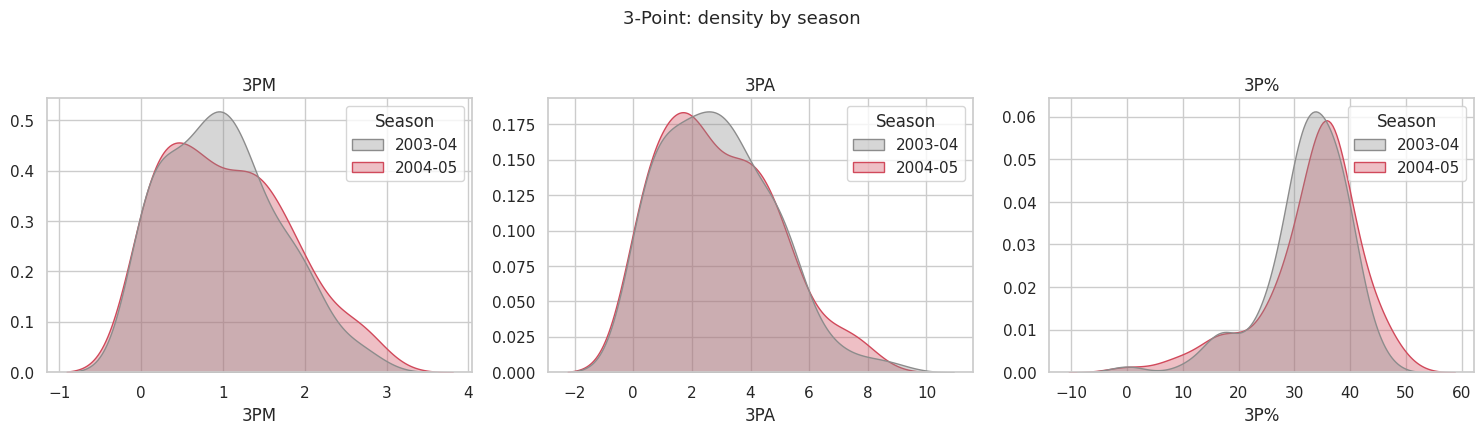

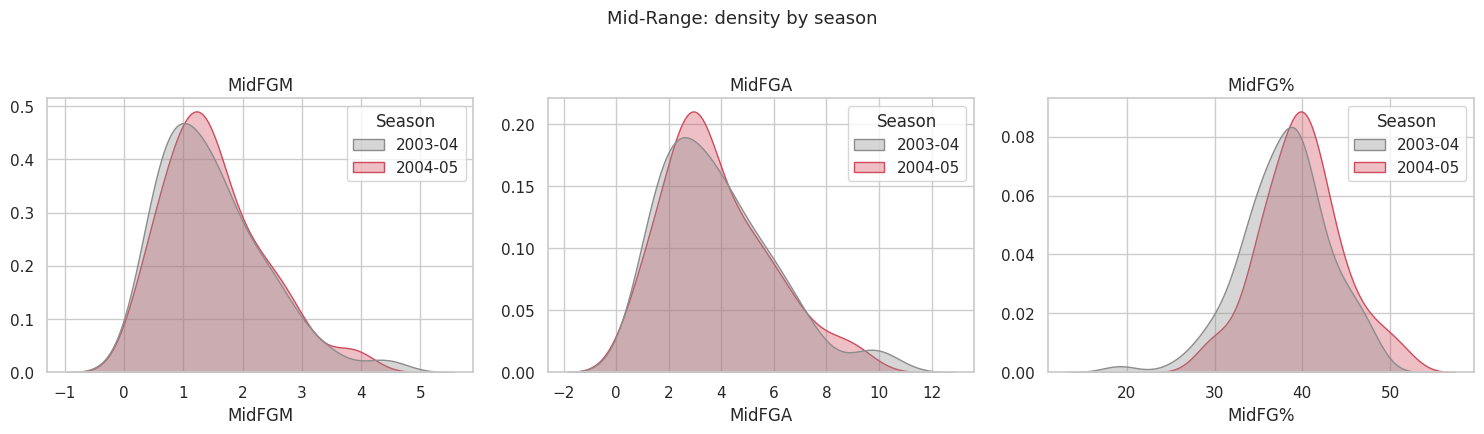

In [6]:
for name, (df, lg) in sets.items():
    grid(lg, f"{name}: density by season", 'density')

Histogram: similar to the density distribution, not smoothed out but y-axis is again probability density. Each bar width: 0.19, 0.57, 3.2, 0.29, 0.65, 2.2, respectively(divided into 15 bars)

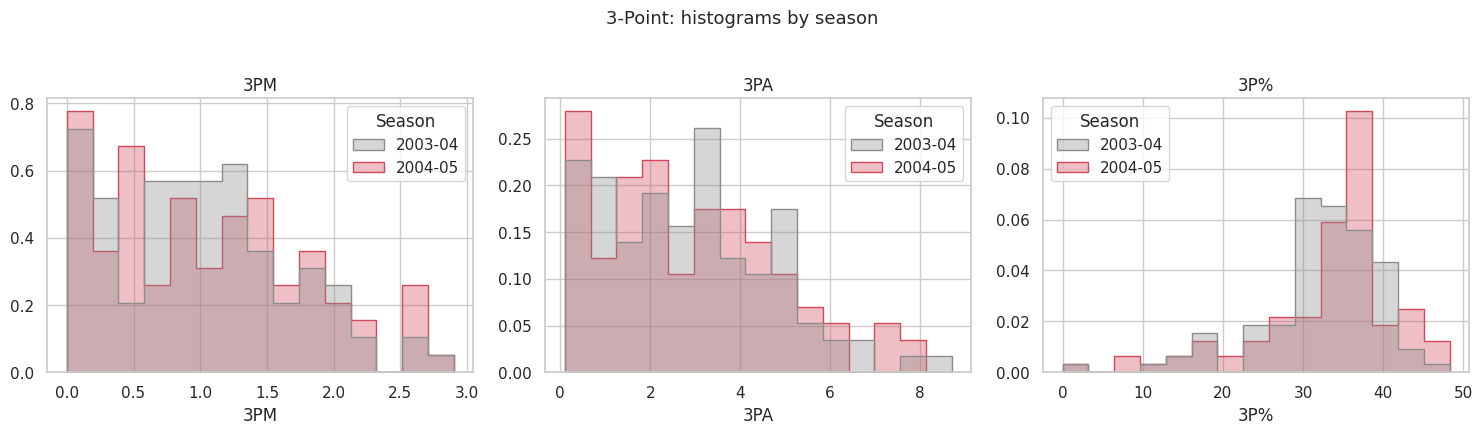

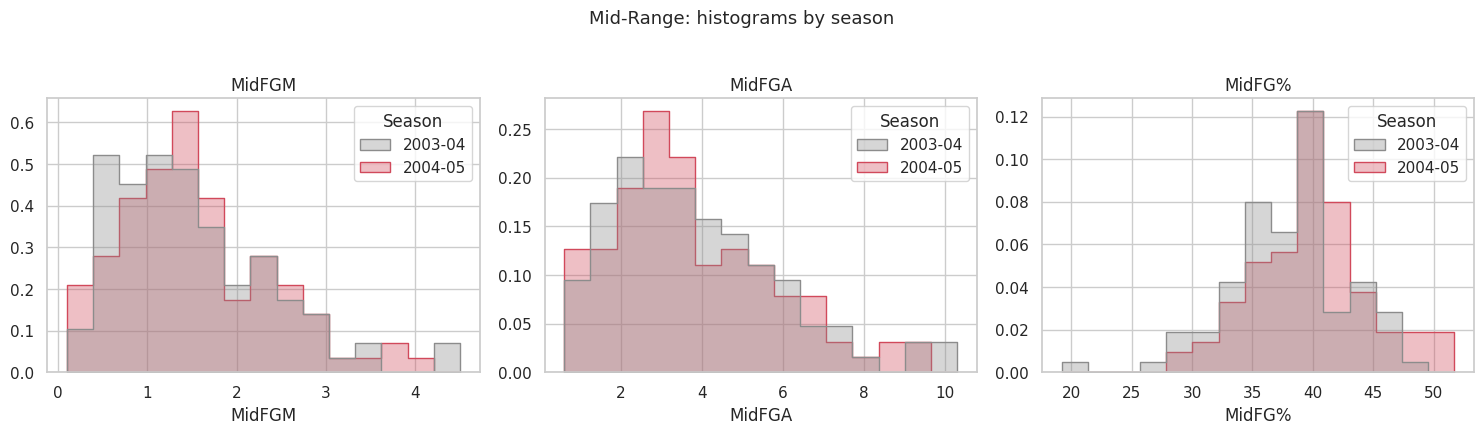

In [7]:
for name, (df, lg) in sets.items():
    grid(lg, f"{name}: histograms by season", 'hist')

Grouped scatter: shows whether stats for each indiivdual player increase or decreased, see most significant difference in 3P% and MidFG%.

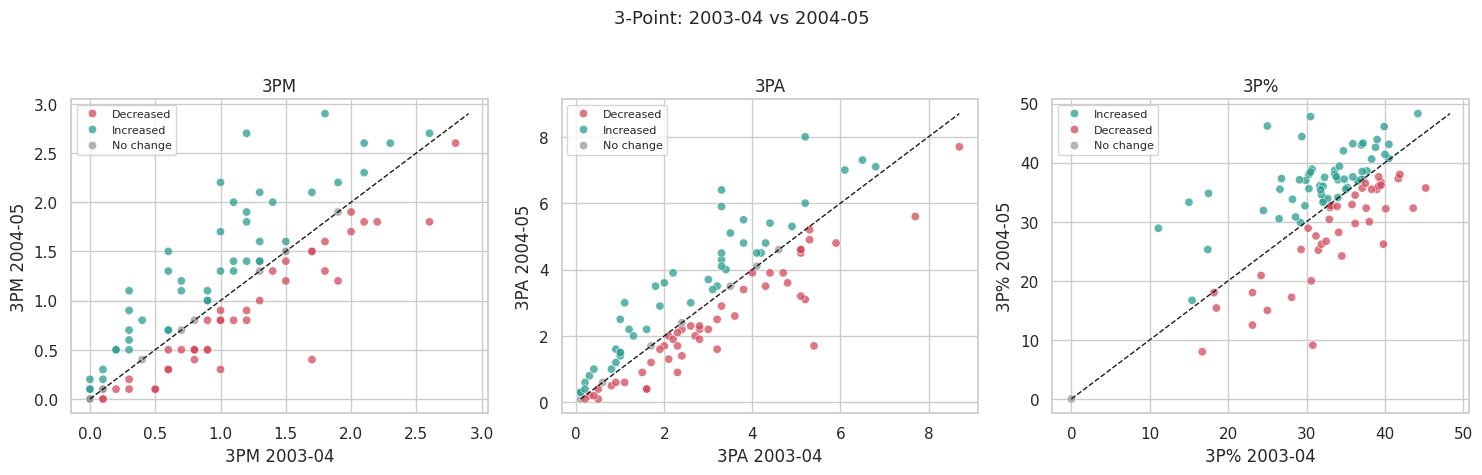

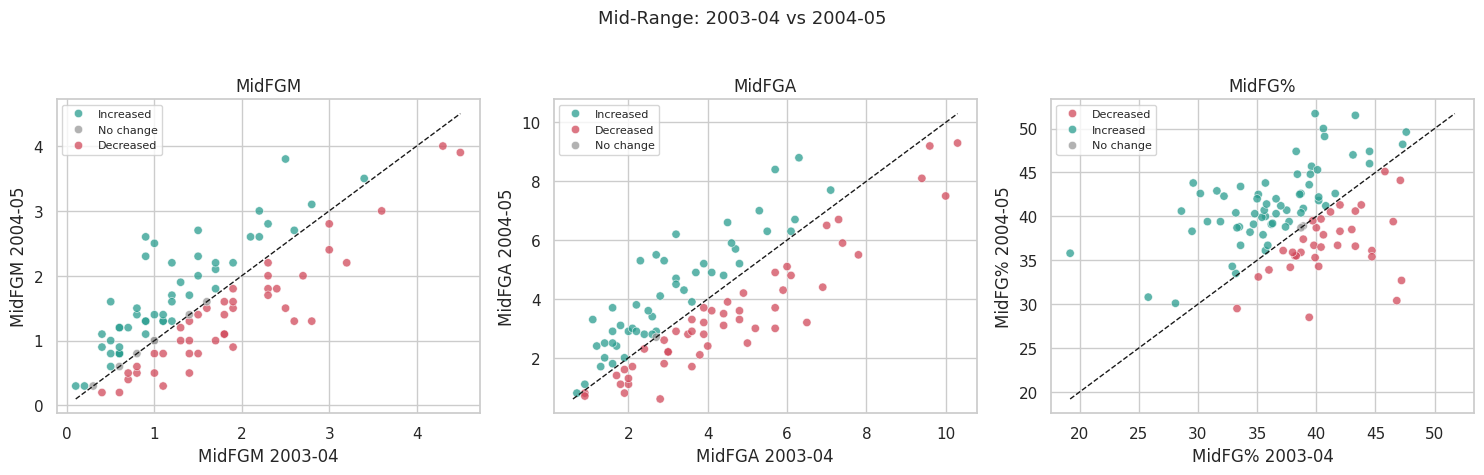

In [8]:
def paired_scatter(df, stats, title):
    fig, axes = plt.subplots(1, len(stats), figsize=(5 * len(stats), 4.6))
    for ax, s in zip(np.atleast_1d(axes), stats):
        x, y = df[f"{s}_0304"], df[f"{s}_0405"]
        grp = np.where(y > x, 'Increased', np.where(y < x, 'Decreased', 'No change'))
        sns.scatterplot(x=x, y=y, hue=grp, palette={'Increased': '#2a9d8f', 'Decreased': '#d1495b', 'No change': '#999999'},
                        alpha=.75, ax=ax)
        lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
        ax.plot([lo, hi], [lo, hi], 'k--', lw=1)
        ax.set_xlabel(f"{s} 2003-04"); ax.set_ylabel(f"{s} 2004-05"); ax.set_title(s)
        ax.legend(title='', fontsize=8)
    fig.suptitle(title, y=1.03, fontsize=13); plt.tight_layout(); plt.show()

paired_scatter(three_df, ['3PM', '3PA', '3P%'], "3-Point: 2003-04 vs 2004-05")
paired_scatter(mid_df, ['MidFGM', 'MidFGA', 'MidFG%'], "Mid-Range: 2003-04 vs 2004-05")

Another grouped scatter showing linear trend between attempts and % (linear regression), interesting that the comparison between the seasons looks the opposite for 3-point and mid-range. For 3-pointers, higher volume indicated higher accuracy for 2004-2005 season relative to the 2003-2004 season. On the contrary, for the mid-range data set, lower volume indicated a higher accuracy for the 2004-2005 season in relative to the 2003-2004 season.

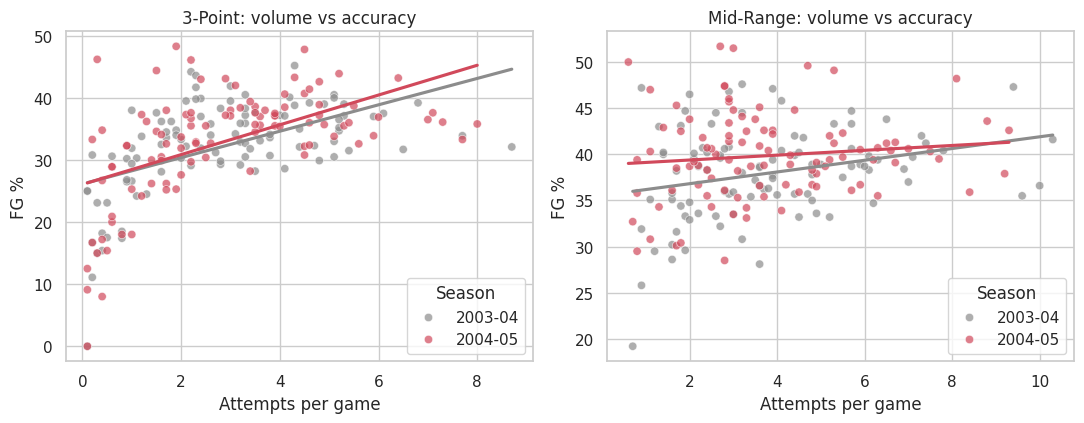

In [9]:
def vol_eff(lg_att, lg_pct, name, ax):
    d = lg_att.merge(lg_pct, on=['Player', 'Season'], suffixes=('_att', '_pct'))
    sns.scatterplot(data=d, x='value_att', y='value_pct', hue='Season', palette=PAL, alpha=.7, ax=ax)
    for season, g in d.groupby('Season'):
        sns.regplot(data=g, x='value_att', y='value_pct', scatter=False, color=PAL[season], ax=ax, ci=None)
    ax.set_xlabel('Attempts per game'); ax.set_ylabel('FG %'); ax.set_title(name)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
vol_eff(three_long['3PA'], three_long['3P%'], '3-Point: volume vs accuracy', axes[0])
vol_eff(mid_long['MidFGA'], mid_long['MidFG%'], 'Mid-Range: volume vs accuracy', axes[1])
plt.tight_layout(); plt.show()

Additionally wanted to look at turnovers and points side-by-side. Points indicaste overall efficiency of the player, turnovers can indicate mistakes that is caused by defensive pressure on guards.

In [11]:
pt_df = m[['clean_name', 'PTS_0304', 'PTS_0405', 'TOV_0304', 'TOV_0405']].copy()
pt_df.columns = ['Player', 'PPG_0304', 'PPG_0405', 'TOV_0304', 'TOV_0405']
pt_df['PPG_change'] = (pt_df['PPG_0405'] - pt_df['PPG_0304']).round(1)
pt_df['TOV_change'] = (pt_df['TOV_0405'] - pt_df['TOV_0304']).round(1)
pt_long = make_long(pt_df, ['PPG', 'TOV'])
print(len(pt_df), "players;", int(pt_df.isna().sum().sum()), "missing values")
print(pd.concat({s: d.groupby('Season')['value'].agg(['mean', 'median', 'std']) for s, d in pt_long.items()}).round(2))
pt_df

100 players; 0 missing values
              mean  median   std
    Season                      
PPG 2003-04  12.17   10.90  5.61
    2004-05  12.60   11.85  6.18
TOV 2003-04   1.87    1.75  0.82
    2004-05   1.79    1.70  0.84


,Player,PPG_0304,PPG_0405,TOV_0304,TOV_0405,PPG_change,TOV_change
0,Jason Terry,16.8,12.4,2.8,1.8,-4.4,-1.0
1,Bob Sura,7.5,10.3,1.3,2.4,2.8,1.1
2,Wesley Person,5.8,6.4,0.7,0.4,0.6,-0.3
3,Boris Diaw,4.5,4.8,1.7,1.3,0.3,-0.4
4,Jacque Vaughn,3.8,5.3,1.2,0.9,1.5,-0.3
...,...,...,...,...,...,...,...
95,Gordan Giricek,11.3,8.8,1.4,1.1,-2.5,-0.3
96,Raul Lopez,7.0,5.2,2.1,1.5,-1.8,-0.6
97,Gilbert Arenas,19.6,25.5,4.1,3.0,5.9,-1.1
98,Larry Hughes,18.8,22.0,2.5,2.5,3.2,0.0


Similar to 3P and Mid-range data sets, composed box plots, probability density, and histograms. -> All data sets clearly show higher ppg and less tov for guards in the 2004-2005 season compared to the 2003-2004 season.

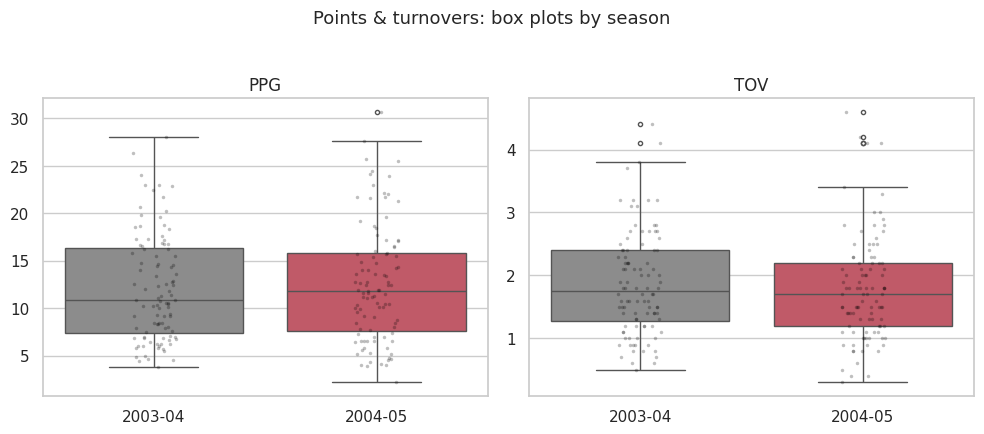

In [12]:
grid(pt_long, "Points & turnovers: box plots by season", 'box')

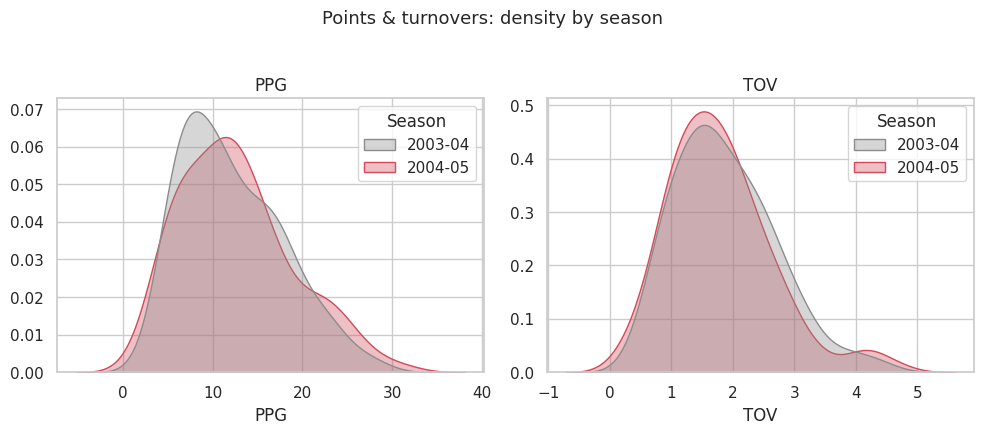

In [13]:
grid(pt_long, "Points & turnovers: density by season", 'density')

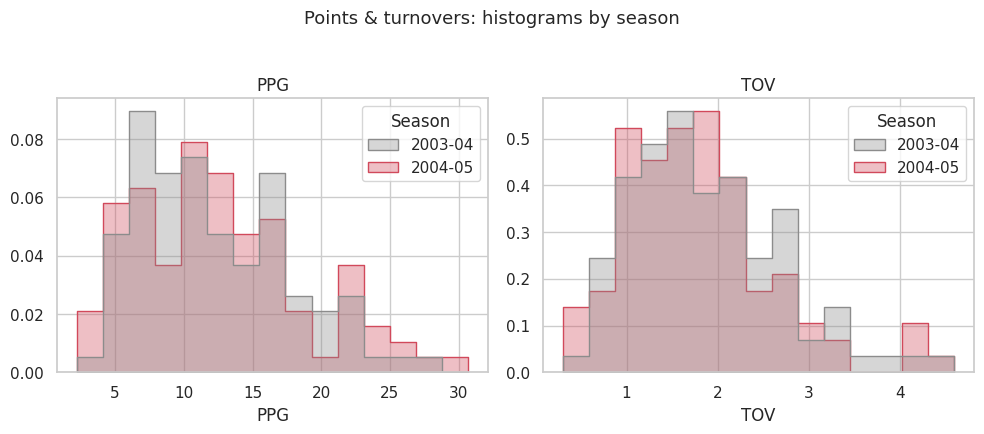

In [14]:
grid(pt_long, "Points & turnovers: histograms by season", 'hist')

More grouped scatter graphs that show whether individual players had higher or lower ppg/tovs between the 2003-2004 and 2004-2005 season. The first two scatters indicate a majority of players experienced higher ppg, but not as many experienced higher tov. The final scatter shows linear trend indicating number of turnovers relative to number of points scored. Obviously, higher points correlate with higher turnovers (more minutes on court).
One major observation: the 2004-2005 guards had less turnovers relative to points scored compared to 2003-2004 guards.
(for fixed number of points guard would score, the expected turnovers would be less)

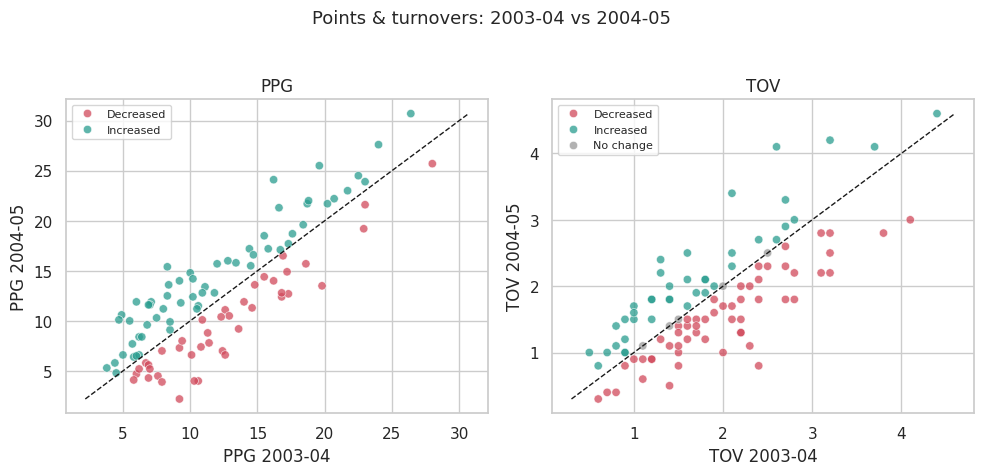

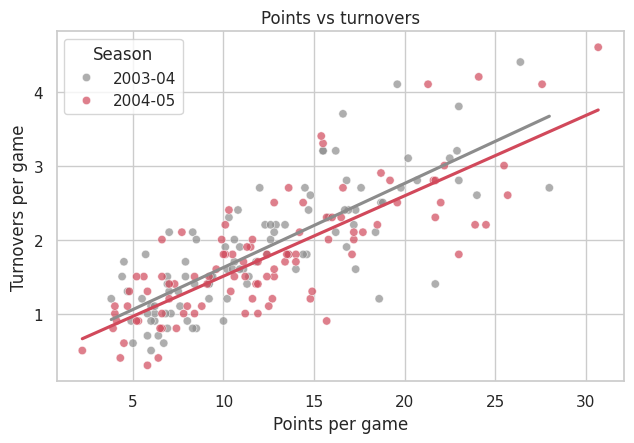

In [15]:
paired_scatter(pt_df, ['PPG', 'TOV'], "Points & turnovers: 2003-04 vs 2004-05")

d = pt_long['PPG'].merge(pt_long['TOV'], on=['Player', 'Season'], suffixes=('_ppg', '_tov'))
fig, ax = plt.subplots(figsize=(6.5, 4.6))
sns.scatterplot(data=d, x='value_ppg', y='value_tov', hue='Season', palette=PAL, alpha=.7, ax=ax)
for season, g in d.groupby('Season'):
    sns.regplot(data=g, x='value_ppg', y='value_tov', scatter=False, color=PAL[season], ax=ax, ci=None)
ax.set_xlabel('Points per game'); ax.set_ylabel('Turnovers per game'); ax.set_title('Points vs turnovers')
plt.tight_layout(); plt.show()